# Generate tuning curve results for fig 1

In [1]:
import imp, sys, os
sys.path.append('../code/')
import numpy as np
import matplotlib.pyplot as plt
import os, sys
import nonlinear_modelv3
import helper_functions
import pupil_dark_helpers as pdh
import seaborn as sns
import pandas as pd

/tmp/ipykernel_2950962/4127301286.py:1: DeprecationWarning: the imp module is deprecated in favour of importlib and slated for removal in Python 3.12; see the module's documentation for alternative uses
  import imp, sys, os


In [2]:
# Set data path
data_path = os.getcwd().replace('analysis/notebooks', 'data/')
print("data path:", data_path)
save_path = os.getcwd().replace('analysis/notebooks', 'data/tuning_curve_data/')
print("save path: ", save_path)

data path: /home/asyeda/stringerlab_dm11/eye-vs-face/data/
save path:  /home/asyeda/stringerlab_dm11/eye-vs-face/data/tuning_curve_data/


### Load data

In [3]:
light_random_dbs = pdh.get_light_random_info()
light_static_dbs = pdh.get_light_static_info()
base_folders = [
    '/home/asyeda/pupil_analysis/light_recordings_random',
    '/home/asyeda/pupil_analysis/light_recordings_static']
dbs = [light_random_dbs, light_static_dbs]
category = ['light_random', 'light_static']
saccade_data = np.load(f'{data_path}/saccade_data/saccade_times.npy', allow_pickle=True).item()

Sessions from get_light_random_info >>>
Sessions from get_light_static_info >>>


Processing mouse:  FXa10
spks (35018, 17247)


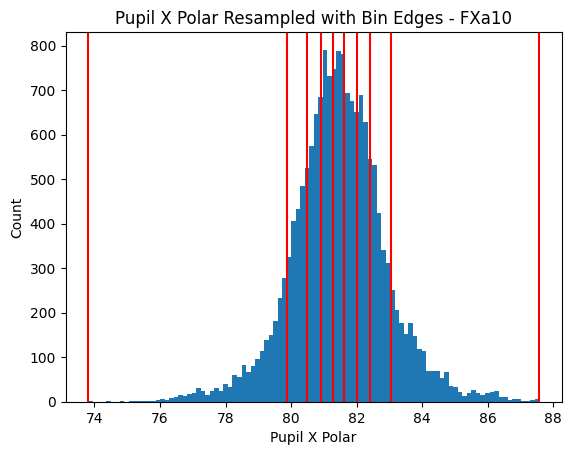

Processing mouse:  FXa8
spks (30801, 17221)


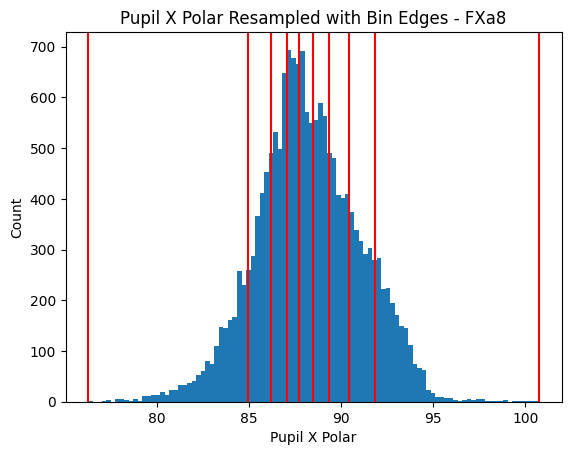

Processing mouse:  FXa9
spks (32109, 17282)


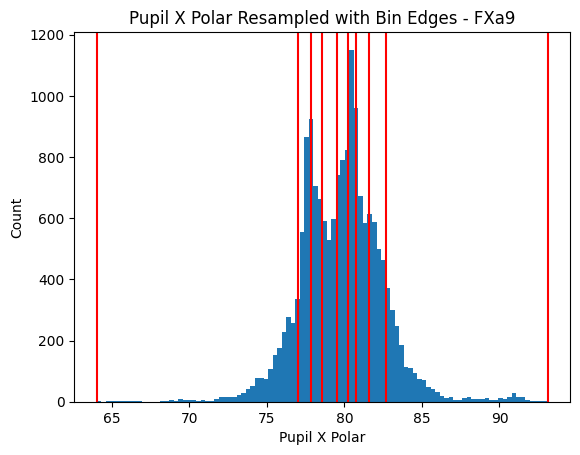

Processing mouse:  LZ16
spks (41961, 17587)


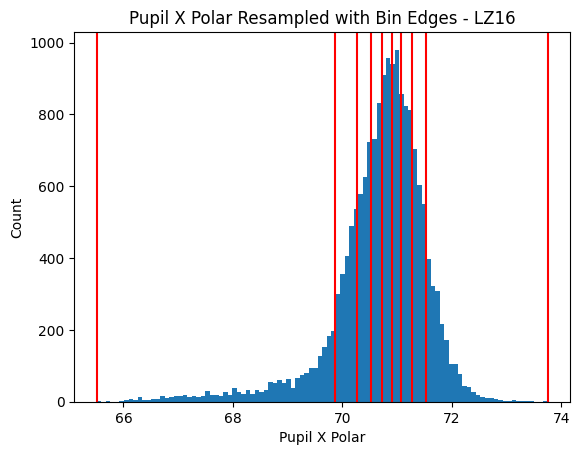

Processing mouse:  TX139
spks (45417, 21802)


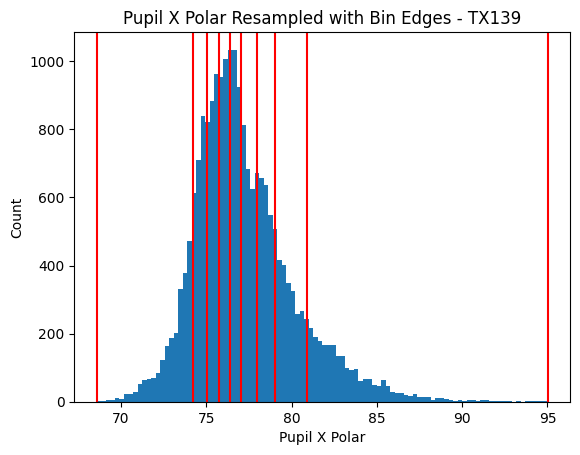

Processing mouse:  TX143
spks (58769, 22698)


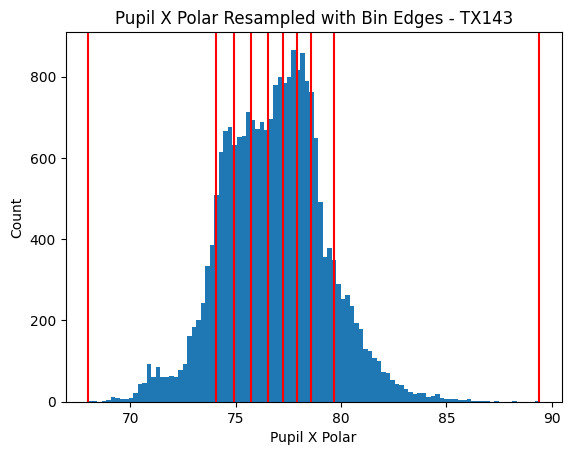

Processing mouse:  TX144
spks (56242, 22553)


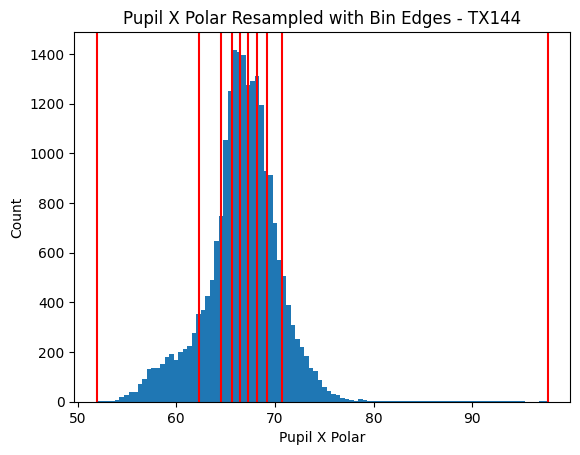

Processing mouse:  FXa1
spks (32414, 19321)


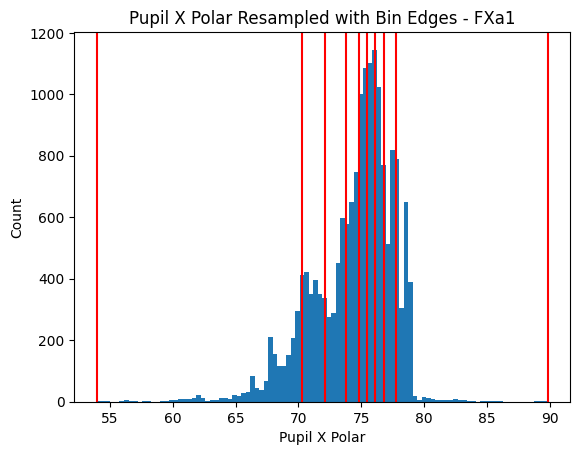

Processing mouse:  FXa10
spks (36668, 19414)


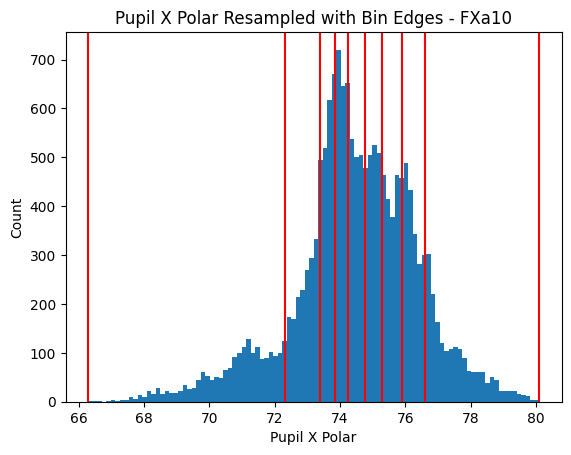

Processing mouse:  FXa8
spks (35167, 19438)


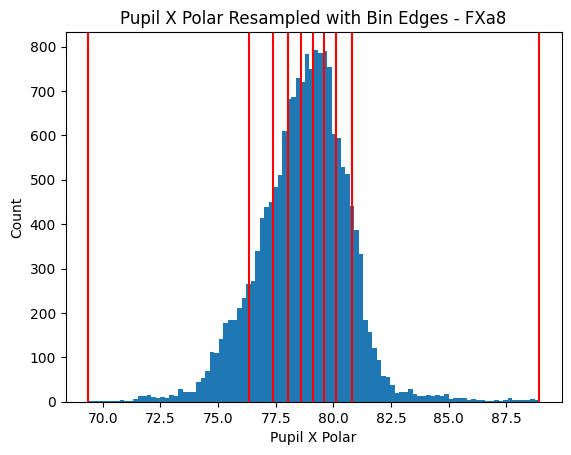

Processing mouse:  LZ16
spks (53268, 13521)


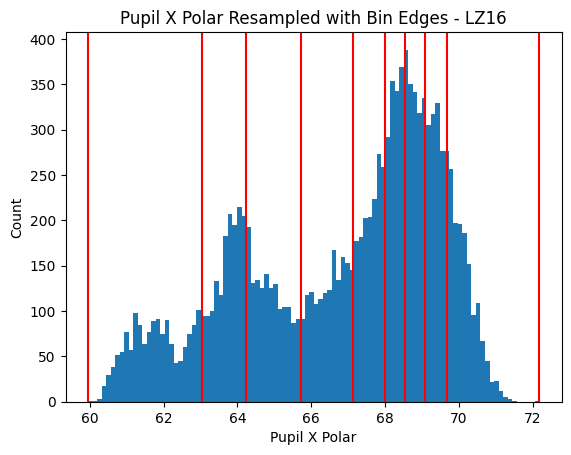

Processing mouse:  TX139
spks (57694, 14196)


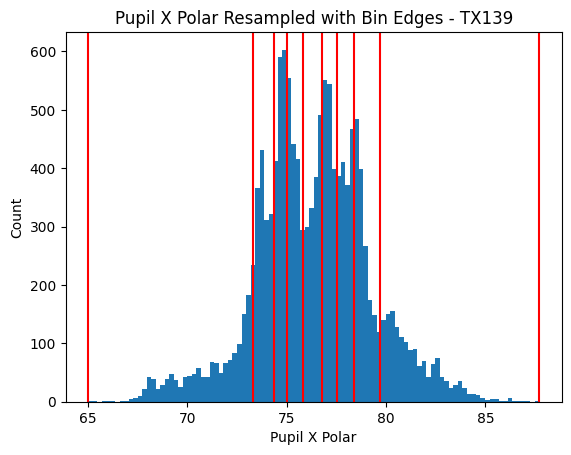

Processing mouse:  TX140
spks (70221, 22852)


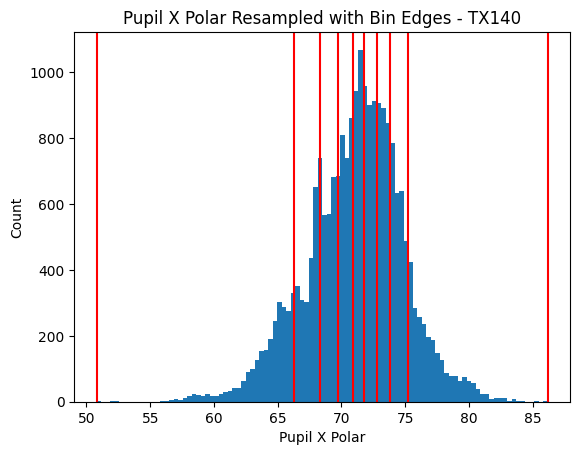

Processing mouse:  TX143
spks (65248, 11264)


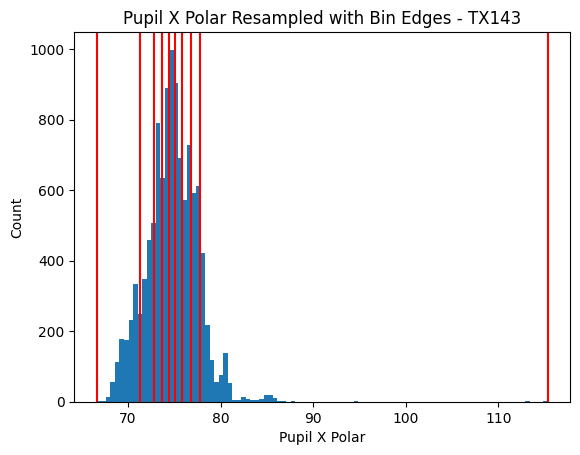

In [8]:
def get_aligned_saccade_idx(saccade_data, spks_timestamps):
    """
    Aligns saccade times to neural timestamps.
    
    Parameters:
    - saccade_data: list of 4 values: saccade_start_idx, saccade_end_idx, saccade_start_t, saccade_end_t
    - spks_timestamps: ndarray of neural timestamps 
    
    Returns:
    - neural_saccade_times: ndarray of shape (N) containing the nearest neural timestamps for each saccade
    """
    saccade_start_t = np.array(saccade_data)[:,2].astype(float)
    saccade_end_t = np.array(saccade_data)[:,3].astype(float)
    # Find nearest neural timestamps to saccade start times
    neural_saccade_start_idx = []
    neural_saccade_end_idx = []
    for i, t in enumerate(saccade_start_t):
        try:
            start_idx = np.argmin(np.abs(spks_timestamps - saccade_start_t[i]))
            end_idx = np.argmin(np.abs(spks_timestamps - saccade_end_t[i]))
            neural_saccade_start_idx.append(start_idx)
            neural_saccade_end_idx.append(end_idx)
        except:
            continue
    return neural_saccade_start_idx, neural_saccade_end_idx

corr_category = {}
mouse_corr_category = {}
category_curve = {}
category_tuning = {}
category_train_data = {}
category_test_data = {}
relative_pupil_position = []
for db_idx, db in enumerate(dbs):
    cat = category[db_idx]
    corr_category[cat] = []
    mouse_corr_category[cat] = {}
    category_curve[category[db_idx]] = np.array([])
    category_tuning[category[db_idx]] = {}
    category_train_data[category[db_idx]] = {}
    category_test_data[category[db_idx]] = {}

    mouse_tuning_train = np.array([])
    mouse_tuning_test = np.array([])
    mouse_preferred_stim = np.array([])
    mouse_relative_positions = np.array([])

    # Get mouse list
    mouse_list = np.unique([entry['mname'] for entry in db])

    for ax_idx, mname in enumerate(mouse_list):
        if "TX150" in mname:
            continue # Different sampling rate
        mouse_corr_category[cat][mname] = []
        print('Processing mouse: ', mname)
        # Get datexp 
        datexp = [entry['datexp'] for entry in db if entry['mname'] == mname][0]
        # Load data
        spks, _, _, _, _, cumframes_neural, cumframes_cam, npz_data = nonlinear_modelv3.load_data(f'{data_path}/npz_data/', mname, datexp) # different base folder for these mice
        print("spks", spks.shape)

        pupil_x_polar = npz_data['pupil_x_polar']
        pupil_y_polar = npz_data['pupil_y_polar']
        pupil_timestamp = npz_data['tcam'].item()['blk1']
        spks_timestamp = npz_data['tneural'].item()['blk1']
        
        # Resample pupil polar x to neural timestamps
        pupil_x_polar = pupil_x_polar[:pupil_timestamp.shape[0]] # trim to match timestamp length
        pupil_x_polar_resampled = helper_functions.interp_value(pupil_x_polar, pupil_timestamp, spks_timestamp)
        exact_saccades = saccade_data[category[db_idx]][mname]['1'] # Get exact saccade indices from precomputed data
        neural_saccade_start_idx, neural_saccade_end_idx = get_aligned_saccade_idx(exact_saccades, spks_timestamp)
        saccade_regions = []
        for sac in range(len(neural_saccade_start_idx)):
            start, end = neural_saccade_start_idx[sac], neural_saccade_end_idx[sac]
            saccade_regions.append(np.arange(start, end+1))
        saccade_regions = np.concatenate(saccade_regions)

        # Divide the pupil x resampled values into 10 bins with same size samples
        bin_edges_pupilx = np.percentile(pupil_x_polar_resampled[~np.isnan(pupil_x_polar_resampled)], np.linspace(0, 100, 10))
        bin_width = np.diff(bin_edges_pupilx)
        bin_centers = (bin_edges_pupilx[:-1] + bin_edges_pupilx[1:]) / 2
        # Plot resampled values and bin edges
        plt.hist(pupil_x_polar_resampled, bins=100)
        for edge in bin_edges_pupilx:
            plt.axvline(edge, color='r')
        plt.title('Pupil X Polar Resampled with Bin Edges - {}'.format(mname))
        plt.xlabel('Pupil X Polar')
        plt.ylabel('Count')
        plt.show()

        # To store relative pupil position of each neuron
        relative_positions_neurons = np.zeros((spks.shape[0],len(bin_centers)), dtype=float) *np.nan

        #spks_mean = np.nanmean(spks, axis=1, keepdims=True)
        spks_std = np.nanstd(spks, axis=1, keepdims=True)
        #spks_normalized = (spks - spks_mean) / (spks_std + 1e-8)
        spks_normalized = spks / spks_std
        
        # Get neural times for bin_edges_pupilx
        all_neural_idx = []
        train_data = []
        test_data = []
        tuning_curves_train = []
        tuning_curves_test = []
        for i in range(len(bin_edges_pupilx)-1):
            bin_start, bin_end = bin_edges_pupilx[i], bin_edges_pupilx[i+1]
            neural_bin_idx = np.where((pupil_x_polar_resampled >= bin_start) & (pupil_x_polar_resampled < bin_end))[0]
            neural_bin_idx = np.setdiff1d(neural_bin_idx, saccade_regions) # exclude saccade periods
            if len(neural_bin_idx) < 4: # remove short segments
                continue

            # Shift by 1 to account for delay (eye movement precedes neural response)
            neural_bin_idx = neural_bin_idx - 1
            neural_bin_idx = neural_bin_idx[neural_bin_idx < spks.shape[1]] # ensure indices within bounds
            neural_bin_idx = neural_bin_idx[neural_bin_idx >= 0]     # remove negative indices

            # Randomly split indices into 2 halves for train and test
            perm = np.random.permutation(neural_bin_idx)
            split = len(perm) // 2
            # ensure equal number of samples in train and test
            train_idx = perm[:split]
            test_idx = perm[split:split*2]
            # assert no overlap between train and test
            assert len(np.intersect1d(train_idx, test_idx)) == 0, "Train and test indices overlap!"
            # assert no overlap between bins
            assert len(np.intersect1d(all_neural_idx, neural_bin_idx)) == 0, "Overlap between bins!"

            # Append to all neural indices to ensure no overlap between bins
            all_neural_idx.extend(neural_bin_idx)

            train_vals = spks_normalized[:, train_idx]
            test_vals = spks_normalized[:, test_idx]

            #mouse_corr_category[cat][mname] = rowwise_corr(train_vals, test_vals)
            # Get average response for each neuron in the bin
            tuning_curves_train.append(np.nanmean(train_vals, axis=1))
            tuning_curves_test.append(np.nanmean(test_vals, axis=1))

            train_data.append(train_vals)
            test_data.append(test_vals)

        train_data = np.hstack(train_data) # neurons x (num_timepoints); num_timepoints = sum of timepoints across all bins
        test_data = np.hstack(test_data)
        tuning_curves_train = np.array(tuning_curves_train).T
        tuning_curves_test = np.array(tuning_curves_test).T
        # Save all train and test data used to compute correlation
        category_train_data[category[db_idx]][mname] = train_data
        category_test_data[category[db_idx]][mname] = test_data

        df1 = pd.DataFrame(train_data)
        df2 = pd.DataFrame(test_data)
        row_wise_correlation = df1.corrwith(df2, axis=1)
            
        corr_category[cat].append(row_wise_correlation)

        preferred_stim = np.argmax(tuning_curves_train, axis=1) # preferred stimulus for each neuron from train trials
        # For each bin in preferred stimulus, get the average tuning curve and relative pupil position
        for bin in range(tuning_curves_test.shape[1]):
            idx_bin = np.where(preferred_stim == bin)[0]  # Select indices in preferred_stim equal to 'bin'
            # Compute the mean and SEM
            mean_curve = np.nanmean(tuning_curves_test[idx_bin], axis=0)  # Compute mean across trials
            sem_curve = np.nanstd(tuning_curves_test[idx_bin], axis=0) / np.sqrt(len(idx_bin))  # Compute SEM
            # for each neuron save the relative position of the bin center to its preferred stimulus
            relative_positions_neurons[idx_bin,:] = bin_centers-bin_centers[bin]

        # Append to mouse tuning list
        if mouse_tuning_train.size == 0:
            mouse_tuning_train = tuning_curves_train
            mouse_tuning_test = tuning_curves_test
            mouse_preferred_stim = preferred_stim
            mouse_relative_positions = relative_positions_neurons
        else:
            mouse_tuning_train = np.vstack((mouse_tuning_train, tuning_curves_train))
            mouse_tuning_test = np.vstack((mouse_tuning_test, tuning_curves_test))
            mouse_preferred_stim = np.hstack((mouse_preferred_stim, preferred_stim))
            mouse_relative_positions = np.vstack((mouse_relative_positions, relative_positions_neurons))

    relative_positions_neurons_bin = np.zeros((mouse_relative_positions.shape[0], mouse_relative_positions.shape[1]+40), dtype=float) *np.nan
    category_tuning[category[db_idx]]['train'] = mouse_tuning_train
    category_tuning[category[db_idx]]['test'] = mouse_tuning_test
    # Get average across mice
    for bin in range(mouse_tuning_test.shape[1]):
        idx_bin = np.where(mouse_preferred_stim == bin)[0]  # Select indices in preferred_stim equal to 'bin'
        # Compute the mean and SEM
        mean_curve = np.nanmean(mouse_tuning_test[idx_bin], axis=0)  # Compute mean across trials
        sem_curve = np.nanstd(mouse_tuning_test[idx_bin], axis=0) / np.sqrt(len(idx_bin))  # Compute SEM

    # Plot one curve after padding with 20 nan and np.roll to center at peak
    for bin in range(tuning_curves_test.shape[1]):
        idx_bin = np.where(mouse_preferred_stim == bin)[0]  # Select indices in preferred_stim equal to 'bin'
        # Compute the mean and SEM
        mean_curve = np.nanmean(mouse_tuning_test[idx_bin], axis=0)  # Compute mean across trials
        padded_curve = np.pad(mean_curve, (20, 20), mode='constant', constant_values=np.nan)
        peak_idx = np.nanargmax(padded_curve)
        centered_curve = np.roll(padded_curve, len(padded_curve)//2 - peak_idx)
        # pad relative_positions_neurons
        relative_positions_neurons_bin[idx_bin,:] = np.pad(mouse_relative_positions[idx_bin,:], ((0,0),(20,20)), mode='constant', constant_values=np.nan)
        relative_positions_neurons_bin[idx_bin,:] = np.roll(relative_positions_neurons_bin[idx_bin,:], (relative_positions_neurons_bin.shape[1])//2 - peak_idx, axis=1)
        if category_curve[category[db_idx]].size:
            category_curve[category[db_idx]] = np.vstack((category_curve[category[db_idx]], centered_curve))
        else:
            category_curve[category[db_idx]] = centered_curve
        relative_pupil_position.append(relative_positions_neurons_bin[idx_bin,:])
relative_pupil_position = np.vstack(relative_pupil_position)

/tmp/ipykernel_2950962/4200528977.py:8: RuntimeWarning: Mean of empty slice
  mean_curve = np.nanmean(average, axis=0)  # Compute mean across trials
/home/asyeda/anaconda3/envs/facemap-tongue/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_2950962/4200528977.py:19: RuntimeWarning: Mean of empty slice
  xticks = np.nanmean(relative_pupil_position, axis=0)


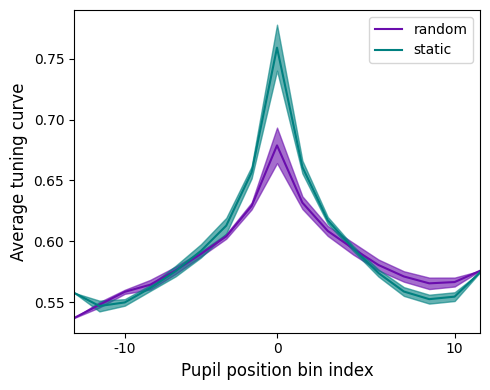

In [9]:
# Plot category curve only
rand_stat_colors = ['#6a0dad', '#008080']
rand_stat_color_names = ['random', 'static']

fig = plt.figure(figsize=(5, 4))
for idx, cat in enumerate(category):
    average = category_curve[cat]
    mean_curve = np.nanmean(average, axis=0)  # Compute mean across trials
    sem_curve = np.nanstd(average, axis=0) / np.sqrt(average.shape[0])  # Compute SEM
    plt.fill_between(range(len(mean_curve)), 
                        mean_curve - sem_curve, 
                        mean_curve + sem_curve, 
                        alpha=0.6, 
                        color=rand_stat_colors[idx])
    plt.plot(range(len(mean_curve)), mean_curve, label=cat.split('_')[1],
             color=rand_stat_colors[idx])
plt.xlabel('Pupil position bin index', fontsize=12)
plt.ylabel('Average tuning curve', fontsize=12)
xticks = np.nanmean(relative_pupil_position, axis=0)
# desired labels in pupil-degree units
desired_tick_vals = [-10, 0, 10]
# ignore NaNs and find the index in padded_xticks closest to each desired value
mask = ~np.isnan(xticks)
valid_idx = np.where(mask)[0]        # indices of non-NaN entries
valid_vals = xticks[mask]     # their values

tick_indices = []
for v in desired_tick_vals:
    # index in valid_vals closest to v, mapped back to original padded indices
    closest_in_valid = np.argmin(np.abs(valid_vals - v))
    tick_indices.append(int(valid_idx[closest_in_valid]))
# set ticks at those index positions, but label them with the pupil-degree values
plt.xticks(tick_indices, [f"{v}" for v in desired_tick_vals])
# set xlim
xlim_vals = [-15, 15]
xlim_indices = []
for v in xlim_vals:
    closest_in_valid = np.argmin(np.abs(valid_vals - v))
    xlim_indices.append(int(valid_idx[closest_in_valid]))
plt.xlim(xlim_indices[0], xlim_indices[1])
plt.legend()
plt.tight_layout()
plt.show()

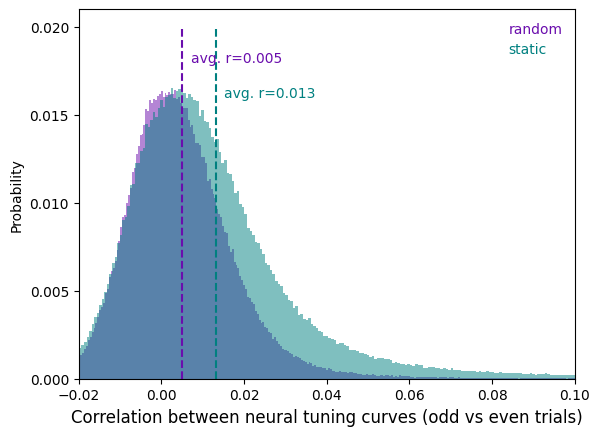

In [10]:
ax = plt.subplot(111)
hist_kws = {'alpha': 0.5, 'edgecolor': 'none', 'stat': 'probability'}  # Changed to 'probability'
for cat in category:
    sns.histplot(np.hstack(corr_category[cat]).flatten(), label=cat.split("_")[1],
                **hist_kws, color=rand_stat_colors[category.index(cat)])
ax.set_xlabel('Correlation between neural tuning curves (odd vs even trials)', fontsize=12)
ax.set_ylabel('Probability')
ax.set_xlim(-0.02, .1)
ax.vlines(np.mean(np.hstack(corr_category['light_random'])), ymin=0, ymax=0.02, colors=rand_stat_colors[0], linestyles='dashed')
ax.vlines(np.mean(np.hstack(corr_category['light_static'])), ymin=0, ymax=0.02, colors=rand_stat_colors[1], linestyles='dashed')
# Add text annotations for mean values
ax.text(np.mean(np.hstack(corr_category['light_random']))+0.002, 0.018, f"avg. r={np.mean(np.hstack(corr_category['light_random'])):.3f}",
        color=rand_stat_colors[0])
ax.text(np.mean(np.hstack(corr_category['light_static']))+0.002, 0.016, f"avg. r={np.mean(np.hstack(corr_category['light_static'])):.3f}",
        color=rand_stat_colors[1])
# reduce yticks
yticks = ax.get_yticks()
ax.set_yticks(yticks[::2])
ax.tick_params(axis='both', which='major')
# Custom legend
legend=ax.legend(frameon=False, loc='upper right', handlelength=0)
for j in range(len(legend.get_texts())):
    legend.get_texts()[j].set_color(rand_stat_colors[j])
legend.get_frame().set_linewidth(0)
for line in legend.get_lines():
    line.set_linewidth(0)
legend.get_frame().set_facecolor('none')

In [ ]:
# Save correlation data
np.save(f'{save_path}correlation_tuning_light_random_static.npy', corr_category)
np.save(f'{save_path}correlation_tuning_light_random_static_permouse.npy', mouse_corr_category)
np.save(f'{save_path}tuning_curve.npy', category_curve)
np.save(f'{save_path}tuning_train_data.npy', category_train_data)
np.save(f'{save_path}tuning_test_data.npy', category_test_data)
np.save(f'{save_path}relative_pupil_position.npy', relative_pupil_position)